C:\Users\fisch\AppData\Local\Temp\ipykernel_21696\3055715228.py:30: RuntimeWarning: divide by zero encountered in log
  ln_c = k*np.log(k) - k +0.5*np.log(2*k*np.pi) + 1/(12*k)
C:\Users\fisch\AppData\Local\Temp\ipykernel_21696\3055715228.py:30: RuntimeWarning: invalid value encountered in multiply
  ln_c = k*np.log(k) - k +0.5*np.log(2*k*np.pi) + 1/(12*k)
C:\Users\fisch\AppData\Local\Temp\ipykernel_21696\3055715228.py:30: RuntimeWarning: divide by zero encountered in divide
  ln_c = k*np.log(k) - k +0.5*np.log(2*k*np.pi) + 1/(12*k)


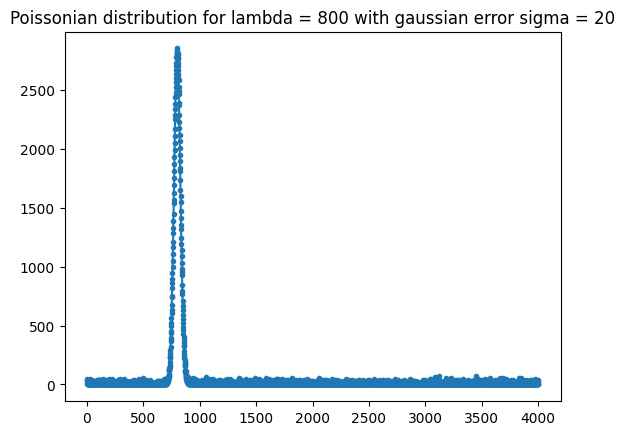

In [39]:
# play around with poissonian
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from scipy.special import factorial

from tof_helper_functions.tof_framework import RawTOFPointList, RebinnedTOFPointList, RawTOFPoint, RebinnedTOFPoint

n = 4000
n_max =  n-1
A = 200000
lam =   800
sigma = 20
k_list = np.linspace(0,n_max,n)

np.random.seed(0) # for reproducibility

def poissonian(k, lam):
    a = pow(lam, k)
    b = np.exp(-lam)
    c = factorial(k)
    return  a*b/c

def poissonian2(A, k, lam): # optimized for large values of k and lam
    ln_a = k* np.log(lam)
    ln_b = -lam
    ln_c = np.log(factorial(k))
    if isinstance(k,np.ndarray):
        if len(k)>500: # Stirling approximation to 4th order for large k
            ln_c = k*np.log(k) - k +0.5*np.log(2*k*np.pi) + 1/(12*k)
    return  A * np.exp(ln_a + ln_b - ln_c)

def poissonian_with_gaussian_err(k, lam, sigma):
    a = pow(lam, k)
    b = np.exp(-lam)
    c = factorial(k)
    return  k + np.random.normal(0,sigma)

gaussian_error_list = [np.random.normal(0,sigma) for i in k_list]
for a in range(len(gaussian_error_list)):
    if gaussian_error_list[a]<0:
        gaussian_error_list[a]=0
poisson_signal_list = poissonian2(A, k_list, lam=lam)
signal_with_noise_list = poisson_signal_list+gaussian_error_list

plt.plot(k_list, signal_with_noise_list, marker='.')
plt.title(f"Poissonian distribution for lambda = {lam} with gaussian error sigma = {sigma}")
#plt.legend()
plt.show()

[np.float64(5.0990195135927845), np.float64(5.196152422706632), np.float64(6.0), np.float64(6.928203230275509), np.float64(5.916079783099616), np.float64(6.164414002968976), np.float64(5.744562646538029), np.float64(6.0), np.float64(6.48074069840786), np.float64(5.0), np.float64(6.0), np.float64(5.830951894845301), np.float64(5.744562646538029), np.float64(6.324555320336759), np.float64(5.744562646538029), np.float64(5.656854249492381), np.float64(5.744562646538029), np.float64(6.855654600401044), np.float64(6.4031242374328485), np.float64(5.196152422706632), np.float64(6.324555320336759), np.float64(5.830951894845301), np.float64(6.557438524302), np.float64(6.0), np.float64(5.5677643628300215), np.float64(5.656854249492381), np.float64(5.477225575051661), np.float64(5.830951894845301), np.float64(6.0), np.float64(5.916079783099616), np.float64(6.0), np.float64(5.830951894845301), np.float64(5.744562646538029), np.float64(6.0), np.float64(5.656854249492381), np.float64(5.65685424949238

Text(0.5, 1.0, 'Raw TOF spectra for delta_t = 0 ms')

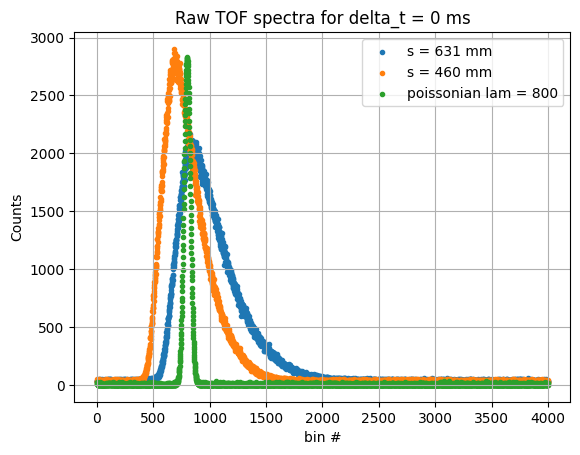

In [ ]:
source_dir = "cascadeTof"

rawdata = pd.read_csv(source_dir+"/TOF_rawdata_dumb.csv", sep='\t')
rawdata_bin = rawdata["Unnamed: 0"]
rawdata_s631 = rawdata["Raw counts [counts/bin]  631 mm tube"]
rawdata_s460 = rawdata["Raw counts [counts/bin] 460 mm tube"]

delta_t = 0
v_max = 15.0
v_min = 3.0
v_step = 0.05
convolution_t = 0.0
convolution_t_err = 0.0
darkcounts_s631 = 0
darkcounts_s631_err = 0
darkcounts_s460 = 0,
darkcounts_s460_err = 0

rawTOF_s631 = RawTOFPointList(rawdata_s631, 
                         s=631, 
                         label = "s = 631 mm", 
                         darkcounts=darkcounts_s631,
                         darkcounts_err=darkcounts_s631_err,
                         delta_t=delta_t,
                         delta_t_err=0.0,
                         convolution_t=convolution_t,
                         convolution_t_err=convolution_t_err)

rebinnedTOF_s631 = RebinnedTOFPointList(rawTOF_s631,
                                   v_min = v_min,
                                   v_max = v_max,
                                   v_step = v_step,
                                   label = "rebinned s = 631 mm")

rawTOF_s460 = RawTOFPointList(rawdata_s460, 
                         s=460, 
                         label = "s = 460 mm", 
                         darkcounts=darkcounts_s460,
                         darkcounts_err=darkcounts_s460_err,
                         delta_t=delta_t,
                         delta_t_err=0.0,
                         convolution_t=convolution_t,
                         convolution_t_err=convolution_t_err)

rebinnedTOF_s460 = RebinnedTOFPointList(rawTOF_s460,
                                   v_min = v_min,
                                   v_max = v_max,
                                   v_step = v_step,
                                   label = "rebinned s = 460 mm")


plt.scatter(rawTOF_s631.bin_number, rawTOF_s631.N_bin, label= rawTOF_s631.label, marker = '.')
plt.scatter(rawTOF_s460.bin_number, rawTOF_s460.N_bin, label= rawTOF_s460.label, marker = '.')
plt.scatter(k_list, signal_with_noise_list, marker='.', label=f"poissonian lam = {lam}")
plt.xlabel("bin #")
plt.ylabel("Counts")
plt.grid(True)
plt.legend()
plt.title(f"Raw TOF spectra for delta_t = {delta_t} ms")